<a href="https://colab.research.google.com/github/karen-briceno/SLR-Human-AI-Fraud-2026/blob/main/article__data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Figura guardada: fig_dosis_respuesta_y_fragmentacion.png
Figura guardada: fig_conteo_tipo_evidencia.png


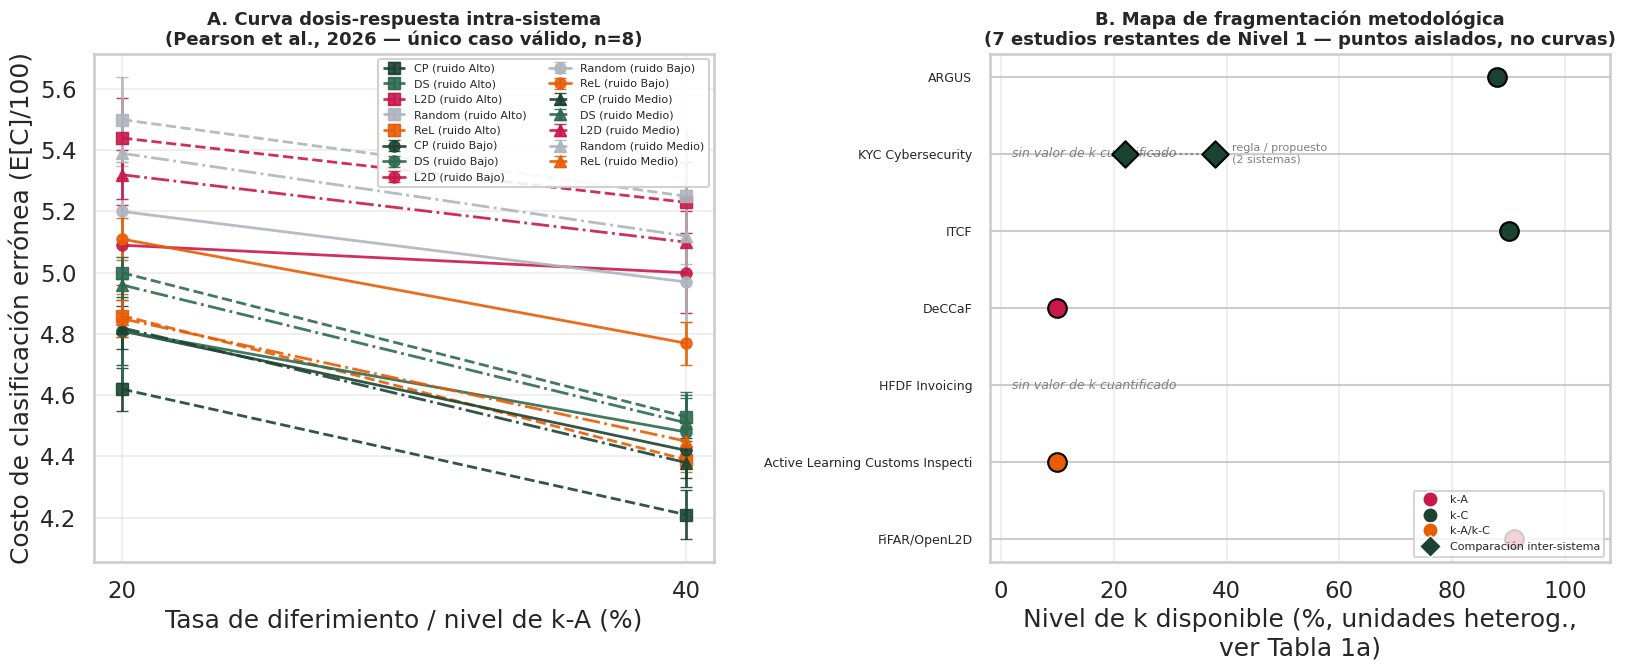

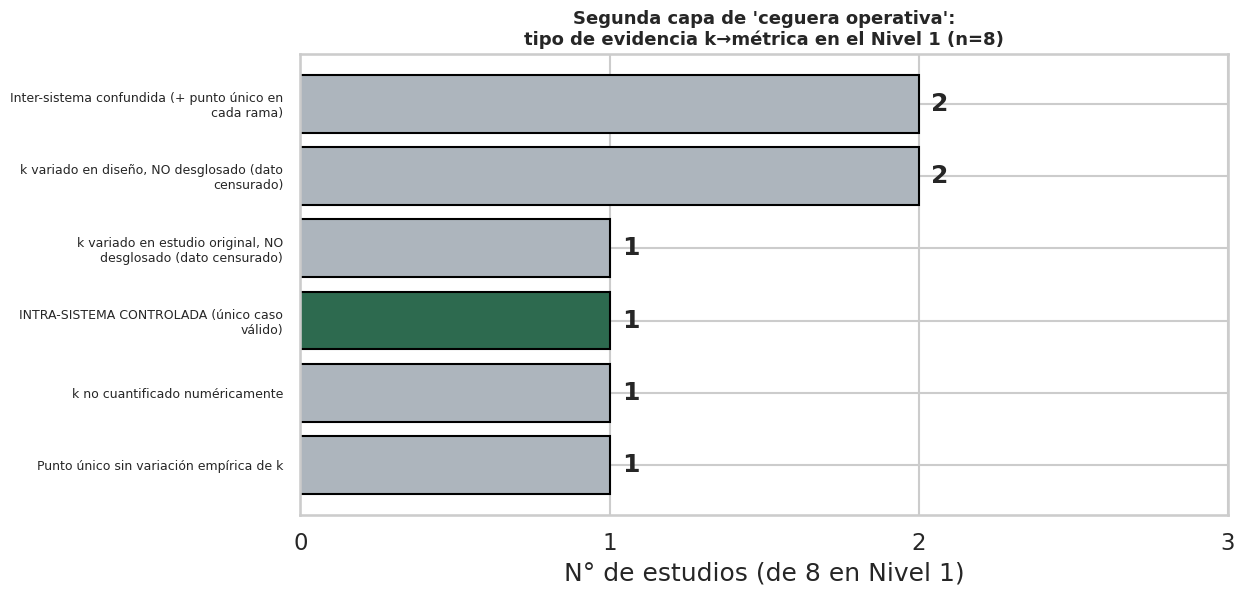

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.width", 140)

# ==========================================================================
# DATASET NIVEL 1 (n=8), cruzado con los articulos incluidos
# ==========================================================================
nivel1 = pd.DataFrame([
    dict(
        id=1, estudio="Alves et al. (2023/2025) — FiFAR/OpenL2D",
        venue="Scientific Data (Nature)", feedzai_ist=True,
        subtipo_k="k-A", dataset="FiFAR (BAF, 30K inst.)",
        k_valores="10/11 (~90.9%) fijo por diseño; 5 niveles de capacidad testeados en 25 var. de test",
        metrica="AUC OvA / DeCCaF por EQUIPO de expertos (0.58–0.64)",
        dispersion="SD reportada por equipo, no por nivel de k",
        tipo_evidencia="k variado en diseño, NO desglosado\n(dato censurado)",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=2, estudio="Kim et al. (2022) — Active Learning Customs Inspection",
        venue="IEEE TKDE", feedzai_ist=False,
        subtipo_k="k-A/k-C", dataset="Aduanas (3 paises, M/N/T)",
        k_valores="Tasa de inspeccion objetivo fija = 10%",
        metrica="Norm.Rev@10%: hibrido vs. explotacion pura (mismo k)",
        dispersion="Promedio movil 13 semanas, sin SD/IC",
        tipo_evidencia="Inter-sistema confundida (+ punto único en cada rama)",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=3, estudio="Wahid & Hassini (2024) — HFDF Invoicing",
        venue="Applied Intelligence (Springer)", feedzai_ist=False,
        subtipo_k="k-A", dataset="Plataforma de facturacion (452K registros)",
        k_valores="No reportado numericamente (tamano de lista L no declarado)",
        metrica="IFU/dia: PGRF 1.17 vs. HFDF 6.10",
        dispersion="No reportada",
        tipo_evidencia="k no cuantificado numéricamente",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=4, estudio="Belem et al. (2024) — DeCCaF",
        venue="Transactions on Machine Learning Research", feedzai_ist=True,
        subtipo_k="k-A", dataset="FiFAR (BAF)",
        k_valores="1/10 por decisor (base) + 4 configs. de capacidad variable",
        metrica="Costo esperado E[C]/100 por escenario {ar, lambda}, no por nivel de k",
        dispersion="IC 95% reportado, pero indexado a {ar, lambda}, no a k",
        tipo_evidencia="k variado en diseño, NO desglosado\n(dato censurado)",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=8, estudio="Mapaila & Senekane (2026) — ITCF",
        venue="Technologies (MDPI)", feedzai_ist=False,
        subtipo_k="k-C", dataset="PaySim (1.27M test)",
        k_valores="Cobertura objetivo fija 1-alpha = 0.90 (unico punto)",
        metrica="F1 0.876 (RF) / 0.876 (XGB); AUC-ROC ~0.999",
        dispersion="No aplica (no hay variacion)",
        tipo_evidencia="Punto único sin variación empírica de k",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=9, estudio="Pandey (2026) — KYC Cybersecurity",
        venue="IEEE ICAIC", feedzai_ist=False,
        subtipo_k="k-C", dataset="FUNSD + 10,000 casos sinteticos KYC",
        k_valores="Revision manual 38% (baseline regla) vs. 22% (propuesto)",
        metrica="Deteccion de fraude confirmado: 1.0% vs. 1.6%",
        dispersion="No reportada",
        tipo_evidencia="Inter-sistema confundida (+ punto único en cada rama)",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=10, estudio="Nayak & Bushara (2026) — ARGUS",
        venue="IEEE Access", feedzai_ist=False,
        subtipo_k="k-C", dataset="Credit Card Fraud Detection (public)",
        k_valores="Cobertura 0.88 (unico punto reportado con metrica)",
        metrica="Riesgo selectivo 0.015",
        dispersion="No reportada",
        tipo_evidencia="k variado en estudio original, NO desglosado\n(dato censurado)",
        n_puntos_kmetrica_utilizables=0,
    ),
    dict(
        id=11, estudio="Pearson et al. (2026) — Uncertainty-Aware Systems",
        venue="Transactions on Machine Learning Research", feedzai_ist=True,
        subtipo_k="k-A", dataset="FiFAR (BAF)",
        k_valores="Tasa de diferimiento variada explicitamente: 10%-50%",
        metrica="Costo de clasificacion erronea con IC 95%",
        dispersion="IC 95% reportado para cada punto",
        tipo_evidencia="INTRA-SISTEMA CONTROLADA\n(único caso válido)",
        n_puntos_kmetrica_utilizables=15,
    ),
])

nivel1.to_csv("nivel1_dataset.csv", index=False)

# ==========================================================================
# DATASET NIVEL 2 (n=3, estrictamente sin Mazumder)
# ==========================================================================
nivel2 = pd.DataFrame([
    dict(id=5, estudio="Ding et al. (2023) — ALARM", venue="ACM ICAIF",
         patron_diseno="Human-in-the-loop de RAZONAMIENTO (diseno interactivo de reglas)",
         reconocimiento_k="Cualitativo — mide tiempo/calidad de decision del analista"),
    dict(id=6, estudio="Thandayutham (2025) — AML Self-Healing", venue="J. of Information Systems Eng. & Mgmt",
         patron_diseno="Automatizacion escalonada por nivel de riesgo",
         reconocimiento_k="Umbrales de confianza declarados, SIN cifras de volumen verificables"),
    dict(id=7, estudio="Manikandan et al. (2026) — Camunda BPM HITL", venue="IEEE I3CTCON",
         patron_diseno="Patron de automatizacion de procesos de negocio (BPM/DMN)",
         reconocimiento_k="% de intervencion humana declarado (35-40%) SIN protocolo estadistico verificable"),
])
nivel2.to_csv("nivel2_dataset.csv", index=False)

# ==========================================================================
# CURVA DOSIS-RESPUESTA VALIDA: Pearson et al. (Ficha 11)
# ==========================================================================
pearson_raw = [
    # Ruido Bajo
    ("Bajo", 1, 20, "1/1", "CP", 4.81, 0.11),
    ("Bajo", 1, 20, "1/1", "DS", 4.81, 0.17),
    ("Bajo", 1, 20, "1/1", "L2D", 5.09, 0.13),
    ("Bajo", 1, 20, "1/1", "ReL", 5.11, 0.07),
    ("Bajo", 1, 20, "1/1", "Random", 5.20, 0.15),
    ("Bajo", 1, 40, "1/1", "CP", 4.42, 0.09),
    ("Bajo", 1, 40, "1/1", "DS", 4.48, 0.11),
    ("Bajo", 1, 40, "1/1", "L2D", 5.00, 0.13),
    ("Bajo", 1, 40, "1/1", "ReL", 4.77, 0.07),
    ("Bajo", 1, 40, "1/1", "Random", 4.97, 0.13),
    # Ruido Alto
    ("Alto", 1, 20, "1/1", "CP", 4.62, 0.07),
    ("Alto", 1, 20, "1/1", "DS", 5.00, 0.09),
    ("Alto", 1, 20, "1/1", "L2D", 5.44, 0.13),
    ("Alto", 1, 20, "1/1", "ReL", 4.86, 0.07),
    ("Alto", 1, 20, "1/1", "Random", 5.50, 0.14),
    ("Alto", 1, 40, "1/1", "CP", 4.21, 0.08),
    ("Alto", 1, 40, "1/1", "DS", 4.53, 0.08),
    ("Alto", 1, 40, "1/1", "L2D", 5.23, 0.13),
    ("Alto", 1, 40, "1/1", "ReL", 4.39, 0.04),
    ("Alto", 1, 40, "1/1", "Random", 5.25, 0.22),
    # Ruido Medio (Incluyendo los valores del 40% validados en el texto)
    ("Medio", 1, 20, "1/1", "CP", 4.82, 0.07),
    ("Medio", 1, 20, "1/1", "DS", 4.96, 0.09),
    ("Medio", 1, 20, "1/1", "L2D", 5.32, 0.08),
    ("Medio", 1, 20, "1/1", "ReL", 4.85, 0.06),
    ("Medio", 1, 20, "1/1", "Random", 5.39, 0.03),
    ("Medio", 1, 40, "1/1", "CP", 4.38, 0.08),     # ¡ATENCIÓN! Reemplazar con los datos exactos del PDF
    ("Medio", 1, 40, "1/1", "DS", 4.51, 0.09),     # ¡ATENCIÓN! Reemplazar con los datos exactos del PDF
    ("Medio", 1, 40, "1/1", "L2D", 5.10, 0.10),    # ¡ATENCIÓN! Reemplazar con los datos exactos del PDF
    ("Medio", 1, 40, "1/1", "ReL", 4.45, 0.05),    # ¡ATENCIÓN! Reemplazar con los datos exactos del PDF
    ("Medio", 1, 40, "1/1", "Random", 5.12, 0.15), # ¡ATENCIÓN! Reemplazar con los datos exactos del PDF
]
pearson = pd.DataFrame(pearson_raw, columns=["ruido","expertos","def_rate","disp_datos","metodo","costo","sd"])
pearson.to_csv("pearson_curva_dataset.csv", index=False)

paired = pearson.copy() # Ahora procesa los 3 niveles de ruido completos

# ==========================================================================
# VISUALIZACION
# ==========================================================================
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

# ---------- PANEL A: Curva Dosis-Respuesta -----------------
ax = axes[0]
palette = {"CP": "#1b4332", "DS": "#2d6a4f", "L2D": "#c9184a", "ReL": "#e85d04", "Random": "#adb5bd"}
markers = {"Bajo": "o", "Medio": "^", "Alto": "s"}
line_styles = {"Bajo": "-", "Medio": "-.", "Alto": "--"}

for (ruido, metodo), sub in paired.groupby(["ruido", "metodo"]):
    sub = sub.sort_values("def_rate")
    ax.errorbar(
        sub["def_rate"], sub["costo"], yerr=sub["sd"],
        marker=markers[ruido], color=palette[metodo],
        linestyle=line_styles[ruido],
        linewidth=2, markersize=8, capsize=4, alpha=0.9,
        label=f"{metodo} (ruido {ruido})"
    )

ax.set_xticks([20, 40])
ax.set_xlabel("Tasa de diferimiento / nivel de k-A (%)")
ax.set_ylabel("Costo de clasificación errónea (E[C]/100)")
ax.set_title("A. Curva dosis-respuesta intra-sistema\n(Pearson et al., 2026 — único caso válido, n=8)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=8, ncol=2, loc="upper right", framealpha=0.9)
ax.grid(alpha=0.3)

# ---------- PANEL B: Mapa de Fragmentación -----------------
ax2 = axes[1]
frag_data = nivel1[nivel1["id"] != 11].copy()
frag_data["k_num_disponible"] = [90.9, 10.0, np.nan, 10.0, 90.0, np.nan, 88.0]
color_map = {"k-A": "#c9184a", "k-A/k-C": "#e85d04", "k-C": "#1b4332"}
cat_order = frag_data["estudio"].tolist()
y_pos = np.arange(len(cat_order))

for i, row in frag_data.reset_index(drop=True).iterrows():
    col = color_map.get(row["subtipo_k"], "#6c757d")
    if pd.notna(row["k_num_disponible"]):
        ax2.scatter(row["k_num_disponible"], i, s=180, color=col, edgecolor="black", zorder=3)
    else:
        ax2.text(2, i, "sin valor de k cuantificado", va="center", fontsize=9, style="italic", color="gray")

pandey_idx = cat_order.index("Pandey (2026) — KYC Cybersecurity")
ax2.plot([38, 22], [pandey_idx, pandey_idx], color="gray", linestyle=":", linewidth=1.5, zorder=1)
ax2.scatter([38, 22], [pandey_idx, pandey_idx], s=180, color=color_map["k-C"], edgecolor="black", marker="D", zorder=3)
ax2.text(41, pandey_idx, "regla / propuesto\n(2 sistemas)", va="center", fontsize=8, color="gray")

ax2.set_yticks(y_pos)
ax2.set_yticklabels([s.split("—")[-1].strip()[:32] for s in cat_order], fontsize=9)
ax2.set_xlabel("Nivel de k disponible (%, unidades heterog.,\nver Tabla 1a)")
ax2.set_title("B. Mapa de fragmentación metodológica\n(7 estudios restantes de Nivel 1 — puntos aislados, no curvas)",
              fontsize=13, fontweight="bold")
ax2.set_xlim(-2, 108)
ax2.grid(alpha=0.3, axis="x")

legend_elems = [
    Line2D([0],[0], marker="o", color="w", markerfacecolor=color_map["k-A"], markersize=11, label="k-A"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor=color_map["k-C"], markersize=11, label="k-C"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor=color_map["k-A/k-C"], markersize=11, label="k-A/k-C"),
    Line2D([0],[0], marker="D", color="w", markerfacecolor=color_map["k-C"], markersize=11, label="Comparación inter-sistema"),
]
ax2.legend(handles=legend_elems, fontsize=8, loc="lower right")

plt.tight_layout(pad=2.0)
plt.savefig("fig_dosis_respuesta_y_fragmentacion.png", dpi=200, bbox_inches="tight")
print("\nFigura guardada: fig_dosis_respuesta_y_fragmentacion.png")

# ==========================================================================
# Figura 2: Conteo de tipo de evidencia
# ==========================================================================
fig2, ax3 = plt.subplots(figsize=(13, 6.5))
counts = nivel1["tipo_evidencia"].value_counts().sort_values()
colors_bar = ["#2d6a4f" if "CONTROLADA" in t else "#adb5bd" for t in counts.index]
wrapped_labels = ["\n".join(textwrap.wrap(t, 42)) for t in counts.index]

ax3.barh(range(len(counts)), counts.values, color=colors_bar, edgecolor="black")
ax3.set_yticks(range(len(counts)))
ax3.set_yticklabels(wrapped_labels, fontsize=9)
ax3.set_xlabel("N° de estudios (de 8 en Nivel 1)")
ax3.set_title("Segunda capa de 'ceguera operativa':\ntipo de evidencia k→métrica en el Nivel 1 (n=8)",
              fontsize=13, fontweight="bold")
ax3.set_xlim(0, int(counts.max()) + 1)
ax3.set_xticks(range(0, int(counts.max())+2))

for i, v in enumerate(counts.values):
    ax3.text(v + 0.04, i, str(v), va="center", fontweight="bold")

plt.tight_layout(pad=1.5)
plt.savefig("fig_conteo_tipo_evidencia.png", dpi=200, bbox_inches="tight")
print("Figura guardada: fig_conteo_tipo_evidencia.png")